# **S3 AGENT ANALYSER**

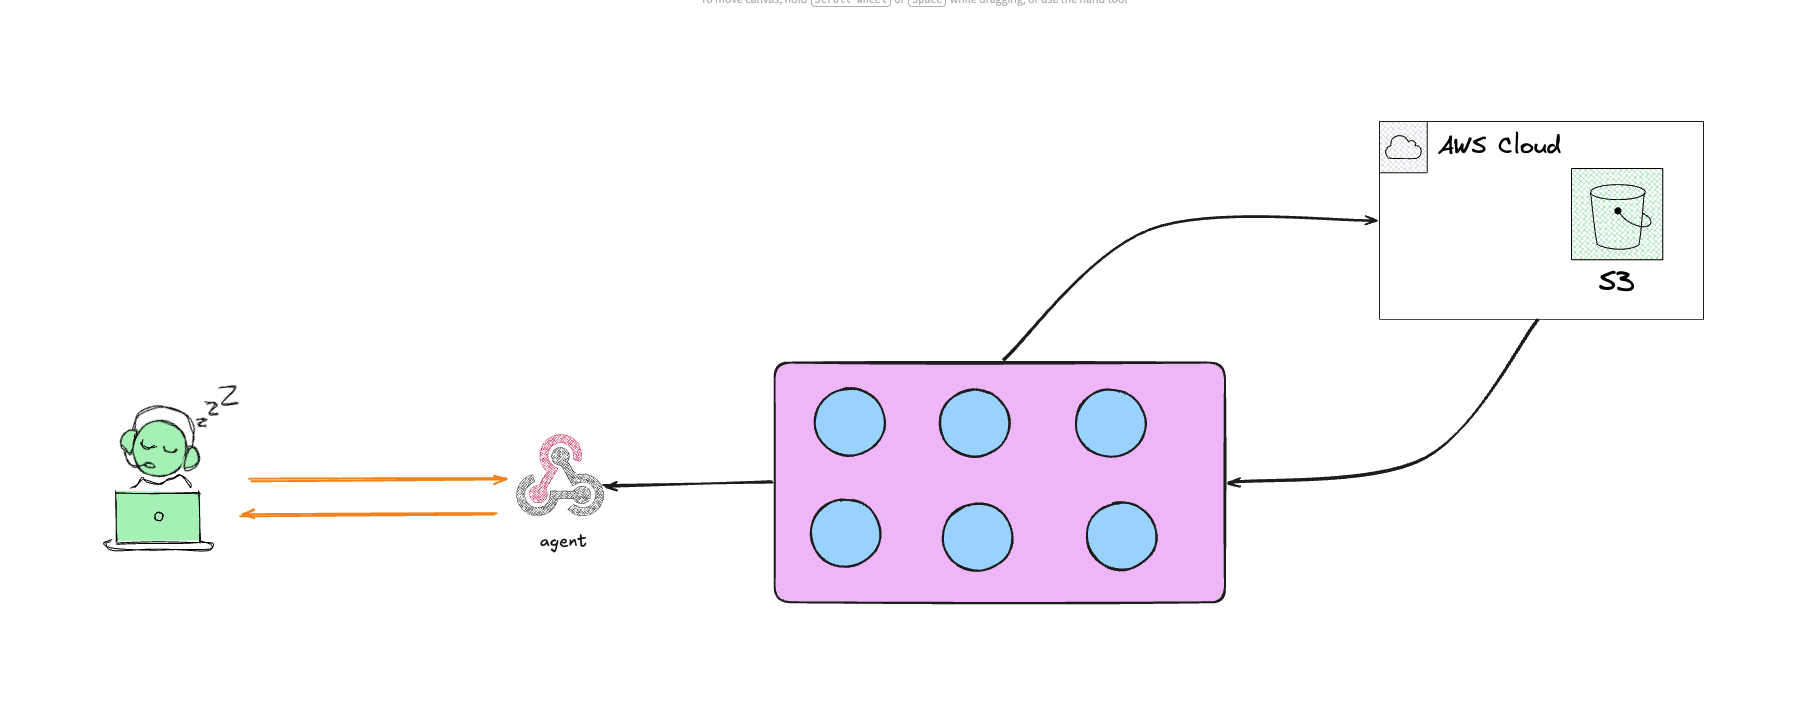

In [ ]:
import boto3
import os
AWS_ACCESS_KEY = "",
AWS_SECRET_KEY = "",
AWS_REGION = "ap-northeast-1"


s3_client = boto3.client(
    "s3",
    aws_access_key_id=AWS_ACCESS_KEY,
    aws_secret_access_key=AWS_SECRET_KEY,
    region_name=AWS_REGION,
)

## **List existing buckets**

In [ ]:
import os
import boto3

s3_client = boto3.client(
    "s3",
    region_name="ap-northeast-1",  # e.g., "us-east-1" or "ap-south-1"
    aws_access_key_id="",
    aws_secret_access_key=""
    # Optional if using temporary/STS credentials:
    # aws_session_token=os.environ.get("AWS_SESSION_TOKEN"),
)

In [61]:
# Retrieve the list of existing buckets
response = s3_client.list_buckets()

# Output the bucket names
print('Existing buckets:')
for bucket in response['Buckets']:
    print(f'  {bucket["Name"]}')

Timestamp: 20261121T121907Z
Timestamp type: <class 'str'>
Region: ap-northeast-1 <class 'str'>
Service: s3 <class 'str'>
Existing buckets:
  itkdemobucket


In [62]:
import os
from collections import defaultdict
from typing import Annotated, Optional, TypedDict

import boto3
from botocore.exceptions import ClientError
import duckdb
from langchain_core.messages import HumanMessage, SystemMessage
from langchain_core.tools import tool
from langchain_openai import ChatOpenAI
from langgraph.graph import END, START, StateGraph
from langgraph.graph.message import add_messages
from langgraph.prebuilt import ToolNode, tools_condition

# Initialize AWS S3 client using default credential chain
s3_client = boto3.client("s3")


def _get_s3_client(region: Optional[str] = None):
    """Return an S3 client scoped to a specific region if provided."""
    if region:
        return boto3.client("s3", region_name=region)
    return s3_client


# ==========================================
# 1. Bucket Management Tools
# ==========================================

@tool
def list_s3_buckets() -> str:
    """List all S3 buckets in the current AWS account along with creation dates."""
    try:
        resp = s3_client.list_buckets()
        buckets = resp.get("Buckets", [])
        if not buckets:
            return "No S3 buckets found in this AWS account."

        lines = [
            f"- {b['Name']} | Created: {b['CreationDate']}" for b in buckets
        ]
        return "\n".join(lines)
    except Exception as e:
        return f"Error listing S3 buckets: {str(e)}"


@tool
def create_s3_bucket(bucket: str, region: Optional[str] = None) -> str:
    """
    Create a new S3 bucket.
    Note: AWS requires LocationConstraint for regions other than us-east-1.
    """
    try:
        effective_region = region or boto3.Session().region_name or "us-east-1"
        client = _get_s3_client(effective_region)

        if effective_region == "us-east-1":
            client.create_bucket(Bucket=bucket)
        else:
            client.create_bucket(
                Bucket=bucket,
                CreateBucketConfiguration={"LocationConstraint": effective_region},
            )
        return f"Successfully created bucket '{bucket}' in region '{effective_region}'."
    except Exception as e:
        return f"Error creating bucket '{bucket}': {str(e)}"


@tool
def delete_s3_bucket(bucket: str, force_empty: bool = False) -> str:
    """
    Delete an S3 bucket.
    Set force_empty=True to delete all objects (and versions, if versioned) before deleting the bucket.
    """
    try:
        if force_empty:
            paginator = s3_client.get_paginator("list_object_versions")
            for page in paginator.paginate(Bucket=bucket):
                to_delete = []
                for v in page.get("Versions", []):
                    to_delete.append({"Key": v["Key"], "VersionId": v["VersionId"]})
                for dm in page.get("DeleteMarkers", []):
                    to_delete.append({"Key": dm["Key"], "VersionId": dm["VersionId"]})
                if to_delete:
                    s3_client.delete_objects(
                        Bucket=bucket, Delete={"Objects": to_delete}
                    )

            obj_paginator = s3_client.get_paginator("list_objects_v2")
            for page in obj_paginator.paginate(Bucket=bucket):
                objs = [{"Key": o["Key"]} for o in page.get("Contents", [])]
                if objs:
                    s3_client.delete_objects(Bucket=bucket, Delete={"Objects": objs})

        s3_client.delete_bucket(Bucket=bucket)
        return f"Successfully deleted bucket '{bucket}'."
    except Exception as e:
        return (
            f"Error deleting bucket '{bucket}': {str(e)}. "
            "If the bucket is not empty, retry with force_empty=True."
        )


# ==========================================
# 2. Bucket Analysis Tool
# ==========================================

@tool
def analyze_s3_bucket(
    bucket: str, prefix: str = "", max_objects_to_scan: int = 5000
) -> str:
    """
    Analyze an S3 bucket (or prefix): total object count, total size, file type breakdown,
    top largest files, and configuration (versioning, encryption, public access block).
    """
    try:
        paginator = s3_client.get_paginator("list_objects_v2")
        total_objects = 0
        total_bytes = 0
        ext_stats = defaultdict(lambda: {"count": 0, "bytes": 0})
        largest_files = []
        truncated_scan = False

        for page in paginator.paginate(Bucket=bucket, Prefix=prefix):
            for obj in page.get("Contents", []):
                if total_objects >= max_objects_to_scan:
                    truncated_scan = True
                    break
                total_objects += 1
                size = obj["Size"]
                key = obj["Key"]
                total_bytes += size

                filename = key.split("/")[-1]
                ext = (
                    f".{filename.split('.')[-1].lower()}"
                    if "." in filename and not filename.startswith(".")
                    else "<no_ext>"
                )
                ext_stats[ext]["count"] += 1
                ext_stats[ext]["bytes"] += size
                largest_files.append((size, key))

            if truncated_scan:
                break

        largest_files.sort(key=lambda x: x[0], reverse=True)
        top_5 = "\n".join(
            f"  - {k} ({s / (1024 * 1024):.2f} MB)" for s, k in largest_files[:5]
        ) or "  - None"

        ext_lines = "\n".join(
            f"  - {ext}: {stats['count']} files ({stats['bytes'] / (1024 * 1024):.2f} MB)"
            for ext, stats in sorted(
                ext_stats.items(), key=lambda item: item[1]["bytes"], reverse=True
            )
        ) or "  - None"

        # Configuration checks
        try:
            loc = s3_client.get_bucket_location(Bucket=bucket).get("LocationConstraint") or "us-east-1"
        except ClientError:
            loc = "unknown"

        try:
            ver = s3_client.get_bucket_versioning(Bucket=bucket).get("Status", "Disabled")
        except ClientError:
            ver = "unknown"

        try:
            enc_rules = s3_client.get_bucket_encryption(Bucket=bucket)[
                "ServerSideEncryptionConfiguration"
            ]["Rules"]
            enc = ", ".join(
                r["ApplyServerSideEncryptionByDefault"]["SSEAlgorithm"] for r in enc_rules
            )
        except ClientError:
            enc = "None/Default"

        try:
            pab = s3_client.get_public_access_block(Bucket=bucket)[
                "PublicAccessBlockConfiguration"
            ]
            pab_summary = f"BlockPublicAcls={pab.get('BlockPublicAcls')}, BlockPublicPolicy={pab.get('BlockPublicPolicy')}"
        except ClientError:
            pab_summary = "Not configured / restricted"

        scan_note = (
            f" (capped at {max_objects_to_scan} objects)" if truncated_scan else ""
        )

        return (
            f"Bucket Analysis for s3://{bucket}/{prefix}{scan_note}\n"
            f"- Region: {loc}\n"
            f"- Versioning: {ver}\n"
            f"- Encryption: {enc}\n"
            f"- Public Access Block: {pab_summary}\n"
            f"- Objects Scanned: {total_objects}\n"
            f"- Total Size: {total_bytes / (1024 * 1024):.2f} MB ({total_bytes / (1024 ** 3):.3f} GB)\n"
            f"- Breakdown by Extension:\n{ext_lines}\n"
            f"- Largest Files:\n{top_5}"
        )
    except Exception as e:
        return f"Error analyzing bucket '{bucket}': {str(e)}"


# ==========================================
# 3. Object Inspection, Query & Mutation Tools
# ==========================================

@tool
def list_s3_objects(bucket: str, prefix: str = "", max_keys: int = 50) -> str:
    """List files (keys), sizes, and last-modified timestamps in an S3 bucket/prefix."""
    try:
        response = s3_client.list_objects_v2(
            Bucket=bucket, Prefix=prefix, MaxKeys=max_keys
        )
        contents = response.get("Contents", [])
        if not contents:
            return f"No objects found in s3://{bucket}/{prefix}"

        lines = [
            f"- {obj['Key']} | Size: {obj['Size'] / 1024:.2f} KB | Modified: {obj['LastModified']}"
            for obj in contents
        ]
        return "\n".join(lines)
    except Exception as e:
        return f"Error listing S3 objects: {str(e)}"


@tool
def inspect_s3_file_preview(bucket: str, key: str, num_bytes: int = 4096) -> str:
    """Read the first few KB of a text/CSV/JSON/log file from S3 to inspect its schema or structure."""
    try:
        response = s3_client.get_object(
            Bucket=bucket, Key=key, Range=f"bytes=0-{num_bytes - 1}"
        )
        data = response["Body"].read().decode("utf-8", errors="replace")
        return f"Preview of s3://{bucket}/{key} (first {num_bytes} bytes):\n\n{data}"
    except Exception as e:
        return f"Error previewing file: {str(e)}"


@tool
def upload_s3_object(
    bucket: str,
    key: str,
    content: Optional[str] = None,
    local_path: Optional[str] = None,
) -> str:
    """
    Upload either inline text `content` or a `local_path` file to s3://{bucket}/{key}.
    Provide either `content` or `local_path`.
    """
    try:
        if local_path:
            s3_client.upload_file(local_path, bucket, key)
            return f"Uploaded local file '{local_path}' to s3://{bucket}/{key}."
        if content is not None:
            s3_client.put_object(Bucket=bucket, Key=key, Body=content.encode("utf-8"))
            return f"Uploaded text content ({len(content)} chars) to s3://{bucket}/{key}."
        return "Error: Provide either `content` or `local_path`."
    except Exception as e:
        return f"Error uploading to s3://{bucket}/{key}: {str(e)}"


@tool
def delete_s3_object(bucket: str, key: str) -> str:
    """Delete a single object at s3://{bucket}/{key}."""
    try:
        s3_client.delete_object(Bucket=bucket, Key=key)
        return f"Deleted s3://{bucket}/{key}."
    except Exception as e:
        return f"Error deleting s3://{bucket}/{key}: {str(e)}"


@tool
def query_s3_with_sql(sql_query: str) -> str:
    """
    Execute a DuckDB SQL query directly against S3 CSV, Parquet, or JSON files.
    Example query: SELECT category, COUNT(*), AVG(price) FROM 's3://my-bucket/sales.parquet' GROUP BY 1 LIMIT 20;
    Always use LIMIT to keep output concise.
    """
    try:
        con = duckdb.connect(database=":memory:")
        con.execute("INSTALL httpfs; LOAD httpfs;")
        session = boto3.Session()
        creds = session.get_credentials().get_frozen_credentials()
        region = session.region_name or "us-east-1"

        con.execute(f"""
            CREATE SECRET (
                TYPE S3,
                KEY_ID '{creds.access_key}',
                SECRET '{creds.secret_key}',
                REGION '{region}'
                {f", SESSION_TOKEN '{creds.token}'" if creds.token else ""}
            );
        """)
        df = con.execute(sql_query).df()
        if len(df) > 100:
            return (
                f"Showing top 100 of {len(df)} rows:\n"
                + df.head(100).to_markdown(index=False)
            )
        return df.to_markdown(index=False)
    except Exception as e:
        return f"SQL Execution Error: {str(e)}"


# ==========================================
# 4. LangGraph Agent Setup
# ==========================================

TOOLS = [
    list_s3_buckets,
    create_s3_bucket,
    delete_s3_bucket,
    analyze_s3_bucket,
    list_s3_objects,
    inspect_s3_file_preview,
    upload_s3_object,
    delete_s3_object,
    query_s3_with_sql,
]


## building state Graph

In [63]:
class graph_schema(TypedDict):
    messages: Annotated[list, add_messages]

In [64]:
llm = ChatOpenAI(model="gpt-4o-mini")
llm_with_tools = llm.bind_tools(TOOLS)

In [65]:
from langchain_core.prompts import ChatPromptTemplate,MessagesPlaceholder
from langchain_openai import ChatOpenAI

def llm_node(state: graph_schema) -> graph_schema:

    messages = state["messages"]

    prompt = ChatPromptTemplate.from_messages(
        [
            (
                "system",
                """
                You are an AWS S3 data and bucket assistant.

                Use the provided S3 tools to:
                - Inspect S3 buckets
                - Create and delete buckets
                - Analyze bucket contents
                - List S3 objects
                - Preview files
                - Upload and delete objects
                - Query CSV and Parquet files using SQL.

                Confirm destructive actions like deleting buckets
                or objects clearly before execution.

                Always keep SQL queries bounded with LIMIT.
                """
            ),
            MessagesPlaceholder(variable_name="messages")
        ]
    )

    chain = prompt | llm_with_tools

    response = chain.invoke({"messages": messages})

    return {
        "messages": [response]
    }

## **TOOL  NODE**

In [66]:
from langchain_core.messages import ToolMessage

def tool_node(state: graph_schema) -> graph_schema:

    messages = state["messages"]

    tools_by_name = {
        tool.name: tool for tool in TOOLS
    }

    tool_result = []

    for tool_call in messages[-1].tool_calls:

        tool = tools_by_name[tool_call["name"]]

        observation = tool.invoke(tool_call["args"])

        tool_result.append(
            ToolMessage(
                content=str(observation),
                tool_call_id=tool_call["id"]
            )
        )

    return {
        "messages": tool_result
    }

## **Conditional Function**

In [67]:
def if_tool_call(state: graph_schema):

    last_message = state["messages"][-1]

    if last_message.tool_calls:
        return "tool_node"

    else:
        return "end"

## BUild Grapha

In [68]:
from langgraph.graph import StateGraph, START, END

graph = StateGraph(graph_schema)

# Add nodes
graph.add_node("llm_node", llm_node)
graph.add_node("tool_node", tool_node)

# Add edges
graph.add_edge(START, "llm_node")

# Conditional routing
graph.add_conditional_edges(
    "llm_node",
    if_tool_call,
    {
        "tool_node": "tool_node",
        "end": END
    }
)

# Return to LLM after tool execution
graph.add_edge("tool_node", "llm_node")

# Compile
react_graph = graph.compile()

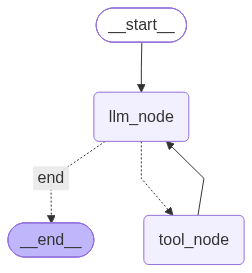

In [69]:
from IPython.display import Image,display

Image(react_graph.get_graph().draw_mermaid_png())

In [70]:
from langchain_core.messages import HumanMessage

response = react_graph.invoke(
    {
        "messages": [
            HumanMessage(
                content="List all S3 buckets in my AWS account"
            )
        ]
    }
)

# Print final response
print(response["messages"][-1].content)

Timestamp: 20261121T121910Z
Timestamp type: <class 'str'>
Region: ap-northeast-1 <class 'str'>
Service: s3 <class 'str'>
You have one S3 bucket in your AWS account:

- **Bucket Name**: itkdemobucket
- **Creation Date**: November 21, 2026, 11:30:56 UTC


In [71]:
from langchain_core.messages import HumanMessage

response = react_graph.invoke(
    {
        "messages": [
            HumanMessage(
                content="can you create s3 bucket"
            )
        ]
    }
)

# Print final response
print(response["messages"][-1].content)

Please provide me with the name you would like for the S3 bucket. If you want it to be created in a specific region other than the default (us-east-1), please specify the region as well.


In [72]:
from langchain_core.messages import HumanMessage

response = react_graph.invoke(
    {
        "messages": [
            HumanMessage(
                content="can you create s3 bucket itks3agentbucket"
            )
        ]
    }
)

# Print final response
print(response["messages"][-1].content)

Timestamp: 20261121T121950Z
Timestamp type: <class 'str'>
Region: ap-northeast-1 <class 'str'>
Service: s3 <class 'str'>
I have successfully created the S3 bucket named **itks3agentbucket** in the region **ap-northeast-1**.


In [73]:
from langchain_core.messages import HumanMessage

response = react_graph.invoke(
    {
        "messages": [
            HumanMessage(
                content="can you delete s3 bucket itks3agentbucket"
            )
        ]
    }
)

# Print final response
print(response["messages"][-1].content)

Deleting an S3 bucket is a destructive action. Before I proceed, can you confirm that you want to delete the bucket named `itks3agentbucket`? Please be aware that this action cannot be undone.
